<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/AI_ExperimentalPhysics/square_triangular_waves_synthesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:65: SyntaxWarning: invalid escape sequence '\p'
<>:65: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_717/1780176937.py:65: SyntaxWarning: invalid escape sequence '\p'
  A[1].set_title("Fourier Mode Amplitudes ($4A / \pi n$)")


k0= 0.3141592653589793
Number of modes? 9
Square or Triangle wave? [s/t]t


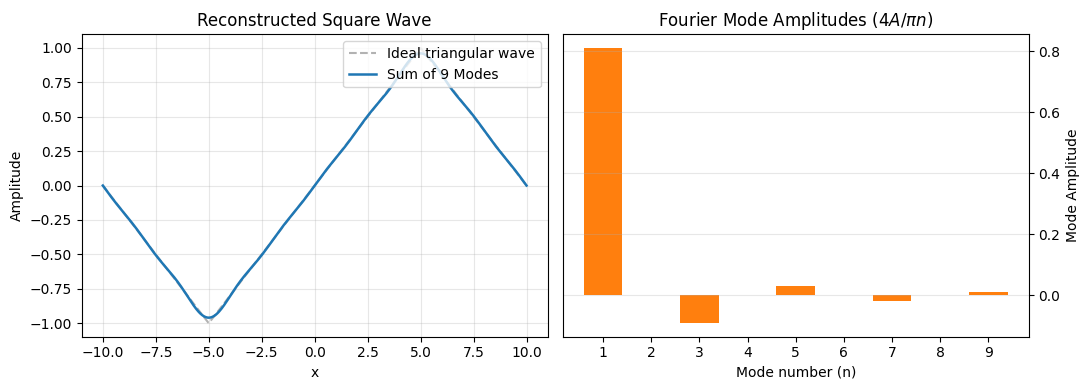

In [27]:
## https://phet.colorado.edu/en/simulations/fourier-making-waves
import numpy as np
import matplotlib.pyplot as plt

# Domain setup
xmax = 10
xmin = -xmax
dist = xmax - xmin
Np = 500
k0 = 2 * np.pi / dist  # Full period across [-xmax, xmax]
print ('k0=',k0)
xspace = np.linspace(xmin, xmax, Np)

Nmodes = 20
Nmodes = int(input('Number of modes? '))
flagW  = input('Square or Triangle wave? [s/t]')

Amplitude = 1.0

# Compute Fourier amplitudes for modes n = 1, 2, ..., Nmodes
### only the odd ones matter
modes = np.arange(1, Nmodes + 1)

Amp_square = np.array([
    (4 * Amplitude / (np.pi * n)) if n % 2 == 1 else 0.0
    for n in modes
])

Amp_triangle = np.array([
    (8 * Amplitude / (np.pi**2 * n**2)) * (-1)**((n-1)/2) if n % 2 == 1 else 0.0
    for n in modes
])

# Reconstruct the square wave by summing the modes
Signal = np.zeros(Np)
if flagW == 's':
  Amp = Amp_square
else:
  Amp = Amp_triangle

for n, aa in zip(modes, Amp):
    if aa != 0:
        Signal += aa * np.sin(n * k0 * xspace)

# Ideal square wave for visual comparison
if flagW == 's':
  ideal_fun = Amplitude * np.sign(np.sin(k0 * xspace))
  labelF = 'Ideal square wave'
if flagW == 't':
  ideal_fun = (2 * Amplitude / np.pi) * np.arcsin(np.sin(k0 * xspace))
  labelF = 'Ideal triangular wave'

# Plot reconstructed wave and mode amplitudes
F, A = plt.subplots(1, 2, figsize=(11, 4))

A[0].plot(xspace, ideal_fun, "--", color="gray", alpha=0.6, label=labelF)
A[0].plot(xspace, Signal, color="tab:blue", linewidth=1.8, label=f"Sum of {Nmodes} Modes")
A[0].set_title("Reconstructed Square Wave")
A[0].set_xlabel("x")
A[0].set_ylabel("Amplitude")
A[0].legend(loc="upper right")
A[0].grid(True, alpha=0.3)

A[1].bar(modes, Amp, color="tab:orange")
A[1].set_title("Fourier Mode Amplitudes ($4A / \pi n$)")
A[1].set_xlabel("Mode number (n)")
A[1].set_xticks(modes)
A[1].yaxis.tick_right()
A[1].yaxis.set_label_position("right")
A[1].set_ylabel("Mode Amplitude")
A[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()